# AML Baseline Training — IBM's Synthetic Dataset

Baseline notebook to detect money laundering using transaction-level and simple entity features

What this does:
- Loads mini CSV, cleans types, derives basic features
- Time-based split (avoid leakage)
- Entity aggregates from train only, merged into test
- Model: LightGBM for now, try random forrest
- Evaluation: PR-AUC, precision/recall at alert budget; top-k alerts table



In [1]:
# All the imports ()
import importlib, subprocess, sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, precision_recall_curve, classification_report
from sklearn.ensemble import RandomForestClassifier

import lightgbm as lgb



### Data Loading

In [3]:
# Configuration
DATA_PATH = '../Datasets/trans_3000p2_list.csv' # 45 million row (use less?)
TARGET_COL = 'Is Laundering'
RANDOM_STATE = 42
ALERT_RATE = 0.001 # 0.1% of scored transactions flagged

print('Data path:', DATA_PATH)


Data path: ../Datasets/trans_3000p2_list.csv


In [4]:
#~1:45

# Load and basic cleaning
df = pd.read_csv(DATA_PATH)
# Strip whitespace from column names and string values
df.columns = df.columns.str.strip()
for c in df.columns:
    if df[c].dtype == 'object':
        df[c] = df[c].astype(str).str.strip()

# Set timestamp to usable date and amounts to numerics (more efficient)
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
for amt_col in ['Amount Received', 'Amount Paid']:
    df[amt_col] = pd.to_numeric(df[amt_col], errors='coerce')

# Drop rows with missing essentials (should be none)
df = df.dropna(subset=['Timestamp', 'Amount Received', 'Amount Paid', TARGET_COL]).copy()
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors='coerce').fillna(0).astype(int)

# Removed sorting due to huggggeee performance issue

print(df.head(3))
print('Rows:', len(df), '| positives:', int((df[TARGET_COL]==1).sum()))


            Timestamp  From Bank    Account    To Bank To Account  \
0 2019-01-01 00:12:00  100417200  8001B5CE0  9127B7340  A7CFB8EC0   
1 2019-01-01 00:07:00  80010CCC0  800123F70  8059F6840  8E24C0DD0   
2 2019-01-01 00:22:00  800319940  8004ED620  808519790  872ABC810   

   Amount Received Receiving Currency  Amount Paid Payment Currency  \
0             3.39          US Dollar         3.39        US Dollar   
1             2.29          US Dollar         2.29        US Dollar   
2           120.92          US Dollar       120.92        US Dollar   

  Payment Format  Is Laundering  
0    Credit Card              0  
1    Credit Card              0  
2    Credit Card              0  
Rows: 45403506 | positives: 55423


### Feature Engineering @ Transaction Level

In [5]:
#~12.5

###########################################
# Feature engineering (transaction level)
# Added:
#   Spread between paid and receieved
#   Is it a change in currency
#   Is it from the same bank 
#   Is it a transfer to own account
#   hour, day of week, weekend or not
###########################################
def build_tx_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out['fx_spread'] = out['Amount Paid'] - out['Amount Received']
    out['is_cross_cur'] = (out['Receiving Currency'] != out['Payment Currency']).astype(int)
    out['same_bank'] = (out['From Bank'] == out['To Bank']).astype(int)
    out['self_transfer'] = (out['Account'] == out['To Account']).astype(int)
    out['hour'] = out['Timestamp'].dt.hour
    out['dow'] = out['Timestamp'].dt.dayofweek
    out['is_weekend'] = out['dow'].isin([5, 6]).astype(int)
    return out

df = build_tx_features(df)
df.head(10)


,Timestamp,From Bank,Account,To Bank,To Account,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,fx_spread,is_cross_cur,same_bank,self_transfer,hour,dow,is_weekend
0,2019-01-01 00:12:00,100417200,8001B5CE0,9127B7340,A7CFB8EC0,3.39,US Dollar,3.39,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0
1,2019-01-01 00:07:00,80010CCC0,800123F70,8059F6840,8E24C0DD0,2.29,US Dollar,2.29,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0
2,2019-01-01 00:22:00,800319940,8004ED620,808519790,872ABC810,120.92,US Dollar,120.92,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0
3,2019-01-01 00:14:00,80010CCC0,8004ED6C0,812962800,86D135520,0.92,US Dollar,0.92,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0
4,2019-01-01 00:26:00,80029A010,8004F16C0,80029A010,8004F16C0,39.24,Euro,45.98,US Dollar,Credit Card,0,6.74,1,1,1,0,1,0
5,2019-01-01 00:26:00,80029A010,8004F16C0,899DFAB00,922F00B80,39.24,Euro,39.24,Euro,Credit Card,0,0.00,0,0,0,0,1,0
6,2019-01-01 00:16:00,8001FF910,8004F73B0,81496AAF0,872ABC7C0,168.05,US Dollar,168.05,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0
7,2019-01-01 00:22:00,80010C840,8004F89A0,82E7CE730,83EEDD580,45.36,US Dollar,45.36,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0
8,2019-01-01 00:10:00,80053C4D0,800A04630,91B51D640,A74CFA880,80.85,US Dollar,80.85,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0
9,2019-01-01 00:14:00,8003044E0,800DC85E0,863FCB240,AF8F43DF0,88.53,US Dollar,88.53,US Dollar,Credit Card,0,0.00,0,0,0,0,1,0


In [6]:
#~30

# Time based split: train = first 80%, test = last 20% by Timestamp (does NOT require the sorting I commented out btw, by quantile)
required_feats = ['fx_spread','is_cross_ccy','same_bank','self_transfer','hour','dow','is_weekend']
if any(f not in df.columns for f in required_feats):
    try:
        df = build_tx_features(df)
    except Exception as _e:
        pass
split_time = df['Timestamp'].quantile(0.80) # <- split here
train_df = df[df['Timestamp'] <= split_time].copy()
test_df  = df[df['Timestamp'] >  split_time].copy()

print('Train rows:', len(train_df), '| Test rows:', len(test_df))
print('Positives (train/test):', int(train_df[TARGET_COL].sum()), int(test_df[TARGET_COL].sum()))


Train rows: 36608479 | Test rows: 8795027
Positives (train/test): 53687 1736


In [7]:
# ~2:30

# For reffence on agg: https://www.w3schools.com/python/pandas/ref_df_agg.asp
# Entity aggregates computed on TRAIN only, then merged into both
def entity_aggs(train: pd.DataFrame, key: str, prefix: str) -> pd.DataFrame:
    tmp = train.copy()
    agg_dict = {
        f'{prefix}_tx_count': ('Timestamp', 'size'),
        f'{prefix}_amt_paid_mean': ('Amount Paid', 'mean'),
        f'{prefix}_amt_recv_mean': ('Amount Received', 'mean'),
        f'{prefix}_cross_ccy_rate': ('is_cross_cur', 'mean'),
    }
    g = tmp.groupby(key).agg(**agg_dict).reset_index()
    return g

acc_aggs   = entity_aggs(train_df, 'Account', 'acc')
toacc_aggs = entity_aggs(train_df, 'To Account', 'toacc')
fb_aggs    = entity_aggs(train_df, 'From Bank', 'fb')
tb_aggs    = entity_aggs(train_df, 'To Bank', 'tb')

def merge_aggs(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame
    out = out.merge(acc_aggs,   on='Account',    how='left')
    out = out.merge(toacc_aggs, on='To Account', how='left')
    out = out.merge(fb_aggs,    on='From Bank',  how='left')
    out = out.merge(tb_aggs,    on='To Bank',    how='left')
    return out

train_df = merge_aggs(train_df)
test_df  = merge_aggs(test_df)

# Fill unseen entities in test with zeros
agg_cols = [c for c in train_df.columns if c.startswith(('acc_', 'toacc_', 'fb_', 'tb_'))]
train_df[agg_cols] = train_df[agg_cols].fillna(0.0)
test_df[agg_cols]  = test_df[agg_cols].fillna(0.0)

len(agg_cols), agg_cols[:6]


(16,
 ['acc_tx_count',
  'acc_amt_paid_mean',
  'acc_amt_recv_mean',
  'acc_cross_ccy_rate',
  'toacc_tx_count',
  'toacc_amt_paid_mean'])

In [8]:
# Feature sets (column info)
numeric_features = [
    'Amount Received', 'Amount Paid', 'fx_spread',
    'is_cross_cur', 'same_bank', 'self_transfer',
    'hour', 'dow', 'is_weekend'
] + [c for c in train_df.columns if c.startswith(('acc_', 'toacc_', 'fb_', 'tb_'))]

categorical_features = ['Payment Format', 'Receiving Currency', 'Payment Currency']

drop_features = ['Timestamp', 'From Bank', 'Account', 'To Bank', 'To Account']

feature_cols = numeric_features + categorical_features

print('Numeric features:', len(numeric_features))
print('Categorical features:', len(categorical_features))
print('Sample features:', feature_cols[:8])


Numeric features: 25
Categorical features: 3
Sample features: ['Amount Received', 'Amount Paid', 'fx_spread', 'is_cross_cur', 'same_bank', 'self_transfer', 'hour', 'dow']


#### OPTIONAL: Offload the engineered training set to local machine

In [ ]:
# Save first 100 for visibility (recommeneded)
test_df.head(100).to_csv('../datasets/engineered_testing_mini.csv')

In [ ]:
# Save entire test and train (NOT recommended ~10GB)

test_df.to_csv("../datasets/engineered_testing.csv")
train_df.to_csv("../datasets/engineered_training.csv")

### Training

In [ ]:
# Preprocessor and model
# Handle OneHotEncoder API changes gracefully across sklearn versions
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocess = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', ohe, categorical_features),
    ],
    remainder='drop'
)

clf = lgb.LGBMClassifier( # Gradient Boosted decision tree
    n_estimators=500,
    learning_rate=0.07, # PR-AUC {0.05:0.223, 0.03, 0.19, 0.227} -> Weird result? Maybe overfitting or going to the wrong local
                        # minimum in the gradient descent?? Strange.
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE, # defined  in cell 2
    class_weight='balanced'
)
# clf = RandomForestClassifier(
#     n_estimators=300,
#     max_depth=None,
#     min_samples_leaf=2,
#     n_jobs=-1,
#     class_weight='balanced_subsample',
#     random_state=RANDOM_STATE
# )

from sklearn import set_config
set_config(transform_output='pandas')

from sklearn.pipeline import make_pipeline
model = make_pipeline(preprocess, clf)

X_train = train_df[feature_cols].copy()
y_train = train_df[TARGET_COL].astype(int).copy()
X_test  = test_df[feature_cols].copy()
y_test  = test_df[TARGET_COL].astype(int).copy()

model.fit(X_train, y_train)
print('Traing complete with LightGBM')


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 53687, number of negative: 36554792
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.376110 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4620
[LightGBM] [Info] Number of data points in the train set: 36608479, number of used features: 62
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Traing complete with LightGBM


### Evaluation

Average Precision (PR-AUC): 0.2273


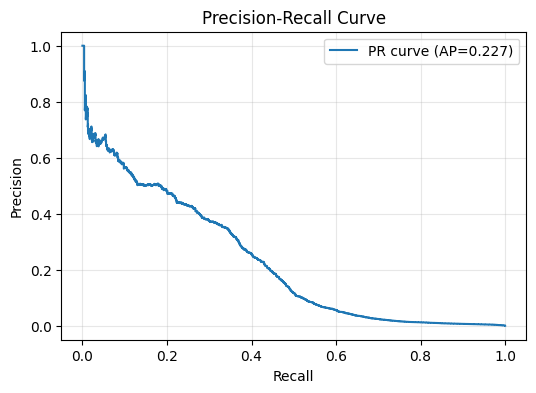

Positives in test: 1736 out of 8795027


In [11]:
# Evaluation: PR-AUC and PR curve
if hasattr(model[-1], 'predict_proba'):
    y_score = model.predict_proba(X_test)[:, 1]
else:
    y_score = model.decision_function(X_test)

ap = average_precision_score(y_test, y_score)
print(f'Average Precision (PR-AUC): {ap:.4f}')

prec, rec, thr = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,4))
plt.plot(rec, prec, label=f'PR curve (AP={ap:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print('Positives in test:', int(y_test.sum()), 'out of', len(y_test))


In [18]:
# Evaluate at alert budget (top-k by score)
def eval_at_alert_rate(y_true: pd.Series, scores: np.ndarray, rate: float = 0.001):
    n = len(scores)
    k = max(1, int(n * rate))
    order = np.argsort(scores)[::-1]
    top_idx = order[:k]
    tp = int(y_true.iloc[top_idx].sum())
    precision = tp / k
    recall = tp / int(y_true.sum()) if int(y_true.sum()) > 0 else np.nan
    return k, precision, recall

k, p_at_k, r_at_k = eval_at_alert_rate(y_test, y_score, rate=ALERT_RATE)
print(f'Alert rate: {ALERT_RATE*100:.3f}% -> top-{k} rows')
print(f'Precision@k: {p_at_k:.4f} | Recall@k: {r_at_k:.4f}')


Alert rate: 0.100% -> top-8795 rows
Precision@k: 0.1020 | Recall@k: 0.5167


In [ ]:
# Feature importance 
final_est = model[-1]
try:
    fe_names = model[0].get_feature_names_out()
except Exception:
    fe_names = [f'f{i}' for i in range(model[0].transform(X_test).shape[1])]

importances = final_est.feature_importances_
imp = (pd.DataFrame({'feature': fe_names, 'importance': importances})
            .sort_values('importance', ascending=False)
            .head(20))
display(imp)



,feature,importance
9,num__acc_tx_count,2446
17,num__fb_tx_count,2398
20,num__fb_cross_ccy_rate,2050
13,num__toacc_tx_count,1950
21,num__tb_tx_count,1753
11,num__acc_amt_recv_mean,1747
10,num__acc_amt_paid_mean,1702
18,num__fb_amt_paid_mean,1516
19,num__fb_amt_recv_mean,1495
14,num__toacc_amt_paid_mean,1466


### Conversion to ONNX

In [43]:
%%capture
# ONNX conversion: LightGBM Pipeline
import os
import numpy as np
import onnx
import onnxruntime as rt
import skl2onnx
import onnxmltools
from skl2onnx import to_onnx, convert_sklearn, update_registered_converter
from skl2onnx.common.shape_calculator import calculate_linear_classifier_output_shapes
from onnxmltools.convert.lightgbm.operator_converters.LightGbm import convert_lightgbm
from lightgbm import LGBMClassifier

# Register LightGBM converter with skl2onnx
update_registered_converter(
    LGBMClassifier,
    'LightGbmLGBMClassifier',
    calculate_linear_classifier_output_shapes,
    convert_lightgbm,
    options={'nocl': [True, False], 'zipmap': [True, False, 'columns']},
)


In [58]:
# Convert the trained pipeline to ONNX
import datetime

onnx_path = f'pipeline_lightgbm_{datetime.datetime.now()}.onnx'
# Prefer to_onnx which infers input schema from a sample (handles DataFrame columns)
# Ensure numeric columns are float32 to avoid double vs float mismatch
X_schema = X_train.iloc[:5].copy()
for col in numeric_features:
    X_schema[col] = X_schema[col].astype(np.float32)
model_onnx = to_onnx(
    model,
    X_schema,
    target_opset={'': 12, 'ai.onnx.ml': 2},
    options={LGBMClassifier: {'zipmap': False}},
)


with open(onnx_path, 'wb') as f:
    f.write(model_onnx.SerializeToString())
print(f'ONNX model saved to: {onnx_path}')


ONNX model saved to: pipeline_lightgbm_2025-11-08 16:03:48.749215.onnx


In [ ]:
# Compare predictions between sklearn pipeline and ONNX
X_sample = X_test.iloc[:500].copy()
print('sklearn predict:', model.predict(X_sample))
print('sklearn predict_proba (first):', model.predict_proba(X_sample)[:1])

sess = rt.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])

# Prepare inputs for onnxruntime
inputs = {}
# Many DataFrame-based conversions produce one ONNX input per column
import re
def norm(s):
    return re.sub(r'[^0-9A-Za-z_]+', '_', s)
for meta in sess.get_inputs():
    name = meta.name
    src = None
    if name in X_sample.columns:
        src = name
    else:
        alt = name.replace('_', ' ')
        if alt in X_sample.columns:
            src = alt
        else:
            nname = norm(name)
            for c in X_sample.columns:
                if norm(c) == nname:
                    src = c
                    break
    if src is None:
        continue
    col = X_sample[src].to_numpy()
    t = meta.type
    if 'tensor(float)' in t or 'tensor(double)' in t:
        col = col.astype(np.float32)
    elif 'tensor(int64)' in t or 'tensor(int)' in t:
        col = col.astype(np.int64)
    elif 'tensor(string)' in t:
        col = col.astype(str).astype(object)
    col = col.reshape((-1, 1))
    inputs[name] = col
missing = [m.name for m in sess.get_inputs() if m.name not in inputs]
if missing:
    raise ValueError(f'Missing required ONNX inputs after mapping: {missing}')
pred_onx = sess.run(None, inputs)


print('onnx predict:', pred_onx[0])
if len(pred_onx) > 1:
    print('onnx predict_proba (first):', pred_onx[1][:1])


sklearn predict: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0